In [8]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import pickle
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, classification_report

In [9]:
class ThreatDetector(nn.Module):
    def __init__(self, input_dim):
        super(ThreatDetector, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        return self.network(x)

# Load original model and scaler
device = torch.device("cpu")
model = ThreatDetector(input_dim=78)
model.load_state_dict(torch.load("../results/threat_detector.pth", map_location=device))
model.eval()

with open("../results/scaler.pkl", "rb") as f:
    scaler = pickle.load(f)

print("Loaded original model and scaler")

Loaded original model and scaler


## Prepare Data

In [12]:
data_dir = "../data/MachineLearningCVE/"

dfs = []

for filename in os.listdir(data_dir):
    if filename.endswith(".csv"):
        temp = pd.read_csv(os.path.join(data_dir, filename), low_memory=False)
        temp.columns = temp.columns.str.strip()
        temp = temp.sample(frac=0.3, random_state=42)
        dfs.append(temp)

df_all = pd.concat(dfs, ignore_index=True)

# Clean
num_cols = df_all.select_dtypes(include=np.number).columns
for col in num_cols:
    df_all[col] = df_all[col].replace([np.inf, -np.inf], np.nan)
df_all.dropna(inplace=True)

# Labels and Features
df_all['binary_label'] = (df_all['Label'].str.strip() != 'BENIGN').astype(int)
X = df_all.drop(columns=['Label', 'binary_label']).values.astype(np.float32)
y = df_all['binary_label'].values

# Scaling using the same scaler from training
X_scaled = scaler.transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42, stratify=y)

print(f"Train: {X_train.shape} | Test: {X_test.shape}")

Train: (678716, 78) | Test: (169679, 78)


## PGD attack

In [14]:
"""
PGD Attack - iterative version of FGSM
epsilon = total allowed perturbation budget
alpha = step size per iteration
num_steps = how many iterations

PGD with margin loss - works better when model is higly confident. 
Instead of CrossEntropy, we directly maximize (logit_benign - logit_attack)
It directly pushes the model toward predicting benign
"""
def pgd_attack(model, X, epsilon, alpha=0.01, num_steps=40):
    X_tensor = torch.tensor(X, dtype=torch.float32)
    X_adv = X_tensor.clone()

    for step in range(num_steps):
        X_adv.requires_grad_(True)

        output = model(X_adv)
        # Margin loss: maximize gap between benign logit and attack logit
        loss = (output[:, 0] - output[:, 1]).mean()
        loss.backward()

        # Small step in gradient direction
        X_adv = X_adv + alpha * X_adv.grad.sign()

        # Project back within epsilon ball - keeps perturbation bounded
        X_adv = torch.clamp(X_adv, X_tensor - epsilon, X_tensor + epsilon)
        X_adv = X_adv.detach()

    return X_adv.numpy()

print("PGD function defined")    # for confirmation

PGD function defined


## Adversarial Training

In [27]:
"""
Adversarial Training - for each training batch:
- Take a batch of clean training data
- Generate PGD adversarial examples from it on the fly
- Mix clean and adversarial example together
- Train on the combined batch

adv_ratio - is the fraction of each batch replaced with adversarial examples
0.5 - means half clean, half adversarial
"""
def adversarial_train(model, X_train, y_train, epochs=10, batch_size=512, lr=1e-3, epsilon=0.1, adv_ratio=0.5):
    model.train()

    class_counts = np.bincount(y_train)
    weights = torch.tensor(1.0 / class_counts, dtype=torch.float32)
    criterion = nn.CrossEntropyLoss(weight=weights)
    optimizer = optim.Adam(model.parameters(), lr=lr)

    train_ds = TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.long)
    )
    loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)

    for epoch in range(1, epochs + 1):
        total_loss = 0.0

        for X_batch, y_batch in loader:
            # Splitting batch into half clean, half becomes adversarial
            split = int(len(X_batch) * adv_ratio)
            X_clean, X_to_attack = X_batch[:split], X_batch[split:]
            y_clean, y_to_attack = y_batch[:split], y_batch[split:]

            # Generating adversarial examples for the attack portion
            model.eval()
            X_adv = pgd_attack(model, X_to_attack.numpy(), epsilon=epsilon, num_steps=10)
            model.train()

            # Combining clean + adversarial
            X_combined = torch.cat([X_clean, torch.tensor(X_adv, dtype=torch.float32)])
            y_combined = torch.cat([y_clean, y_to_attack])

            optimizer.zero_grad()
            loss = criterion(model(X_combined), y_combined)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        print(f"Epoch {epoch:02d}/{epochs} | Loss: {total_loss/len(loader):.4f}")

    return model
print("Adversarial training function defined")

Adversarial training function defined


## Hardened Model

In [28]:
# Fresh model
hardened_model = ThreatDetector(input_dim=78).to(device)

print("Starting Adversarial Training...")
print("(This will take several minutes - each batch generate PGD examples)\n")

hardened_model = adversarial_train(
    hardened_model,
    X_train, y_train,
    epochs=10,
    batch_size=512,
    epsilon=0.1,
    adv_ratio=0.5
)

print("\nAdversarial Training Complete!")

Starting Adversarial Training...
(This will take several minutes - each batch generate PGD examples)

Epoch 01/10 | Loss: 0.1325
Epoch 02/10 | Loss: 0.1024
Epoch 03/10 | Loss: 0.0941
Epoch 04/10 | Loss: 0.0895
Epoch 05/10 | Loss: 0.0858
Epoch 06/10 | Loss: 0.0837
Epoch 07/10 | Loss: 0.0825
Epoch 08/10 | Loss: 0.0810
Epoch 09/10 | Loss: 0.0797
Epoch 10/10 | Loss: 0.0777

Adversarial Training Complete!


## Original vs Hardened Model

In [34]:
def eval_under_attack(model, X_test, y_test, epsilon=0.1):
    # Run PGD attack then measure accuracy
    # Only attack the attack examples
    attack_mask = y_test == 1
    X_attacks = X_test[attack_mask]
    y_attacks = y_test[attack_mask]

    X_adv = pgd_attack(model, X_attacks, epsilon=epsilon, num_steps=40)

    adv_tensor = torch.tensor(X_adv, dtype=torch.float32)
    loader = DataLoader(TensorDataset(adv_tensor), batch_size=1024)

    preds = []
    with torch.no_grad():
        for(X_batch,) in loader:
            out = model(X_batch)
            preds.extend(out.argmax(1).numpy())

    acc = (np.array(preds) == y_attacks).mean()
    return acc

epsilons = [0.01, 0.05, 0.1, 0.2, 0.3]

print("Benchmarking both models under PGD attack... \n")

original_accs = []
hardened_accs = []

for eps in epsilons:
    print(f"Testing epsilon={eps:.2f}...")
    orig_acc = eval_under_attack(model, X_test, y_test, epsilon=eps)
    hard_acc = eval_under_attack(hardened_model, X_test, y_test, epsilon=eps)
    original_accs.append(orig_acc)
    hardened_accs.append(hard_acc)
    print(f"Original: {orig_acc:.1%} | Hardened: {hard_acc:.1%}")

Benchmarking both models under PGD attack... 

Testing epsilon=0.01...
Original: 97.3% | Hardened: 25.1%
Testing epsilon=0.05...
Original: 65.1% | Hardened: 25.9%
Testing epsilon=0.10...
Original: 40.7% | Hardened: 27.7%
Testing epsilon=0.20...
Original: 32.2% | Hardened: 28.9%
Testing epsilon=0.30...
Original: 22.1% | Hardened: 28.7%


## Fine-Tune Original Model

In [39]:
import copy

hardened_model2 = ThreatDetector(input_dim=78)
hardened_model2.load_state_dict(torch.load("../results/threat_detector.pth", map_location=device))     # starting from already-trained model

print("Fine-tuning from orginal model weights...")
print("(adv_ratio=0.3, lr=1e-4 (less aggressive than before))\n")

hardened_model2 = adversarial_train(
    hardened_model2,
    X_train, y_train,
    epochs=10,
    batch_size=512,
    lr=1e-4,                  # lower learning rate - preserve exisitng knowledge
    epsilon=0.1,
    adv_ratio=0.3             # less adversarial - 30% instead of 50%
)

print("\nFine-Tuning Complete!")

Fine-tuning from orginal model weights...
(adv_ratio=0.3, lr=1e-4 (less aggresive than before))

Epoch 01/10 | Loss: 0.1161
Epoch 02/10 | Loss: 0.0897
Epoch 03/10 | Loss: 0.0847
Epoch 04/10 | Loss: 0.0811
Epoch 05/10 | Loss: 0.0800
Epoch 06/10 | Loss: 0.0783
Epoch 07/10 | Loss: 0.0775
Epoch 08/10 | Loss: 0.0763
Epoch 09/10 | Loss: 0.0757
Epoch 10/10 | Loss: 0.0751

Fine-Tuning Complete!


## Checking Clean Accuracy

In [40]:
print("Original model (clean data):")
evaluate_clean(model, X_test, y_test)

print("\nHardened model 2 - fine-tuned (clean data):")
evaluate_clean(hardened_model2, X_test, y_test)

Original model (clean data):
  Overall accuracy:   96.7%
  Predicting benign:  130,956 (77.2%)
  Predicting attack:  38,723 (22.8%)

Hardened model 2 - fine-tuned (clean data):
  Overall accuracy:   94.1%
  Predicting benign:  126,478 (74.5%)
  Predicting attack:  43,201 (25.5%)


## Benchmarking under PGD attack

In [42]:
print("Benchmarking original vs fine-tuned model under PGD attack...\n")

original_accs  = []
hardened_accs  = []

for eps in epsilons:
    print(f"Testing epsilon={eps:.2f}...")
    orig_acc = eval_under_attack(model, X_test, y_test, epsilon=eps)
    hard_acc = eval_under_attack(hardened_model2, X_test, y_test, epsilon=eps)
    original_accs.append(orig_acc)
    hardened_accs.append(hard_acc)
    print(f"  Original: {orig_acc:.1%} | Hardened: {hard_acc:.1%}")

Benchmarking original vs fine-tuned model under PGD attack...

Testing epsilon=0.01...
  Original: 97.3% | Hardened: 99.8%
Testing epsilon=0.05...
  Original: 65.1% | Hardened: 99.5%
Testing epsilon=0.10...
  Original: 40.7% | Hardened: 84.0%
Testing epsilon=0.20...
  Original: 32.2% | Hardened: 65.3%
Testing epsilon=0.30...
  Original: 22.1% | Hardened: 56.4%


## Final Comparison Plot

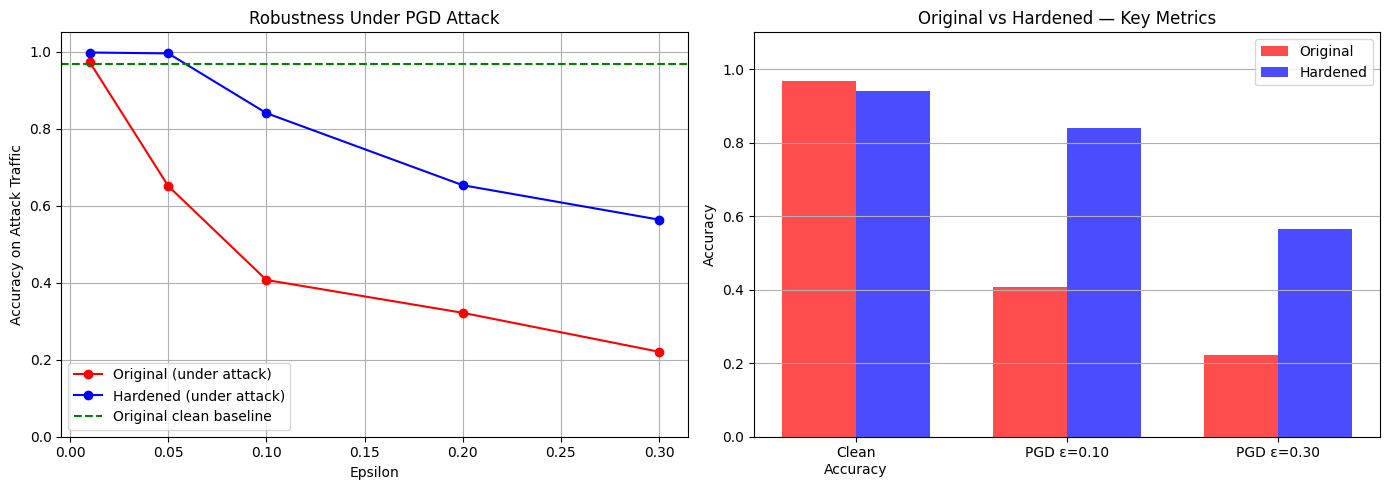


Final Summary:
Clean accuracy:    Original 96.7% → Hardened 94.1% (-2.6%)
PGD ε=0.10:        Original 40.7% → Hardened 84.0% (+43.3%)
PGD ε=0.30:        Original 22.1% → Hardened 56.4% (+34.3%)


In [43]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: under attack
axes[0].plot(epsilons, original_accs,  marker='o', color='red',   label='Original (under attack)')
axes[0].plot(epsilons, hardened_accs,  marker='o', color='blue',  label='Hardened (under attack)')
axes[0].axhline(y=0.967, color='green', linestyle='--', label='Original clean baseline')
axes[0].set_title("Robustness Under PGD Attack")
axes[0].set_xlabel("Epsilon")
axes[0].set_ylabel("Accuracy on Attack Traffic")
axes[0].set_ylim(0, 1.05)
axes[0].legend()
axes[0].grid(True)

# Right: clean vs adversarial tradeoff summary
categories = ['Clean\nAccuracy', 'PGD ε=0.10', 'PGD ε=0.30']
orig_vals   = [0.967, 0.407, 0.221]
hard_vals   = [0.941, 0.840, 0.564]

x = np.arange(len(categories))
width = 0.35
axes[1].bar(x - width/2, orig_vals, width, label='Original', color='red',  alpha=0.7)
axes[1].bar(x + width/2, hard_vals, width, label='Hardened', color='blue', alpha=0.7)
axes[1].set_title("Original vs Hardened — Key Metrics")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1.1)
axes[1].set_xticks(x)
axes[1].set_xticklabels(categories)
axes[1].legend()
axes[1].grid(True, axis='y')

plt.tight_layout()
os.makedirs("../results", exist_ok=True)
plt.savefig("../results/defense_comparison.png", dpi=150, bbox_inches='tight')
plt.show()

print("\nFinal Summary:")
print(f"Clean accuracy:    Original {0.967:.1%} → Hardened {0.941:.1%} (-2.6%)")
print(f"PGD ε=0.10:        Original {original_accs[2]:.1%} → Hardened {hardened_accs[2]:.1%} (+{hardened_accs[2]-original_accs[2]:.1%})")
print(f"PGD ε=0.30:        Original {original_accs[4]:.1%} → Hardened {hardened_accs[4]:.1%} (+{hardened_accs[4]-original_accs[4]:.1%})")

## Save Hardened Model

In [44]:
torch.save(hardened_model2.state_dict(), "../results/hardened_threat_detector.pth")
print("Hardened model saved in results/hardened_threat_detector.pth")

Hardened model saved in results/hardened_threat_detector.pth
